# Figueredo, Kevin — Release-View v1

Static stills from the hitter's batter's-box POV for each pitch type:
1. **Release frame** — pitcher silhouette + release-point cloud + average ball at release
2. **Commit-point frame** — ball position 175 ms before the plate

Anchor pitch = middle-middle four-seam (or sinker / cutter if four-seam too thin). Secondaries fall back to a competitive-zone average if middle-middle is short on sample. 2026 weighted 3× vs 2025.

## v1 caveats
- Arm angle is a single input parameter — plug in the output of your RF model. Default below is a placeholder.
- Pitcher height is hand-entered. Pull from your players table when you wire that up.
- Run `diagnose_coords` on the pulled data to confirm sign conventions match Statcast. If signs are flipped in your data, follow the diagnostic message instructions.

In [1]:
import release_view as rv
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

OUTPUT_DIR = Path('output/figueredo_v1')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## 1. Pull pitches

Make sure `FLCommand.env` is in this directory (or one level up). Expected vars: `SUPABASE_HOST`, `SUPABASE_USER`, `SUPABASE_PASSWORD`, optionally `SUPABASE_PORT` and `SUPABASE_DATABASE`.

In [2]:
import os
print(os.path.exists(r'C:/Users/215nt/PycharmProjects/FLStuff/FLPitching/FLCommand.env'))

False


In [3]:
engine = rv.get_engine(r'C:/Users/215nt/PycharmProjects/FLStuff/FLPitching/FLCommand/.env')
df = rv.pull_pitcher_pitches(engine, 'Figueredo', years=(2025, 2026))
print(f'Pulled {len(df)} pitches')
print(df['year'].value_counts().sort_index())
print()
print(df['pitch_type'].value_counts())

Pulled 186 pitches
year
2026    186
Name: count, dtype: int64

pitch_type
sinker      119
slider       50
changeup     17
Name: count, dtype: int64


## 2. Verify coordinate convention

Figueredo is LHP, so we expect `x0` to be **positive** (1B side) and `y0` around 50–55 ft. If signs are reversed, follow the printed instructions before rendering.

In [4]:
rv.diagnose_coords(df)

[diagnose] left: n=186, mean x0=+2.90, y0=+50.00, z0=+5.30
  Statcast expects: R hand -> x0 negative (3B side), L hand -> x0 positive (1B side).


## 3. Pick anchor + build references for each pitch type

In [5]:
anchor = rv.primary_fastball(df)
print(f'Anchor pitch type: {anchor}')

refs = {}
for pt in df['pitch_type'].value_counts().index:
    is_anchor = (pt == anchor)
    ref = rv.get_reference_pitch(df, pt, is_anchor=is_anchor)
    if ref is None:
        print(f'  {pt}: insufficient sample, skipping')
        continue
    refs[pt] = ref
    p = ref['params']
    t_plate = rv.time_to_plate(p)
    print(f'  {pt}: n={ref["n"]:3d} ({ref["location_filter"]:>16s}) | '
          f'release=({p["x0"]:+.2f}, {p["z0"]:.2f}) | '
          f'velo={np.sqrt(p["vx0"]**2+p["vy0"]**2+p["vz0"]**2)/1.467:.1f} mph | '
          f't_plate={t_plate*1000:.0f} ms')

Anchor pitch type: sinker
  sinker: n= 26 (   middle-middle) | release=(+2.92, 5.28) | velo=87.0 mph | t_plate=397 ms
  slider: n= 24 (competitive zone) | release=(+2.91, 5.44) | velo=75.7 mph | t_plate=455 ms
  changeup: insufficient sample, skipping


## 4. Set pitcher-specific params

**Plug in your RF-model arm-angle output here.** Height in inches.

In [6]:
PITCHER_NAME = 'Figueredo, Kevin'
PITCHER_HEIGHT_IN = 73          # 6'1" — REPLACE with actual
ARM_ANGLE_DEG = 55              # placeholder — REPLACE with your RF-model output
THROWING_HAND = 'L'

PITCHER_HEIGHT_FT = PITCHER_HEIGHT_IN / 12.0

# League-average hitter height for the still — adjust per opposing lineup later
HITTER_HEIGHT_IN = 72

In [7]:
# Optional: Override style defaults directly in the notebook
STYLE_OVERRIDES = {
    'jersey_color': '#1d3324',     # Deep green for home team jersey
    'pants_color': '#e6e6e6',      # Traditional road gray/white pants
    'glove_color': '#4a3319',      # Classic brown leather glove
    'ball_scale': 2.5,             # Blow up ball size for vision tracking printouts
    'fov_deg': 16.0                # 16.0 = Zoomed tight on pitcher; 22.0 = Wide angle stadium context
}

## 5. Render every pitch type, both hitter handednesses

Saves to `output/figueredo_v1/` and displays inline.

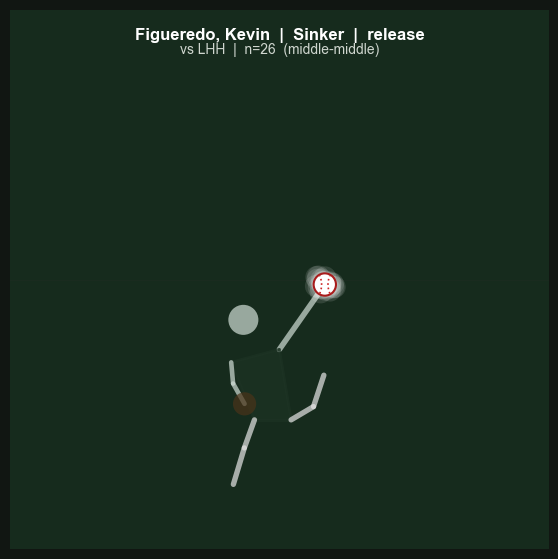

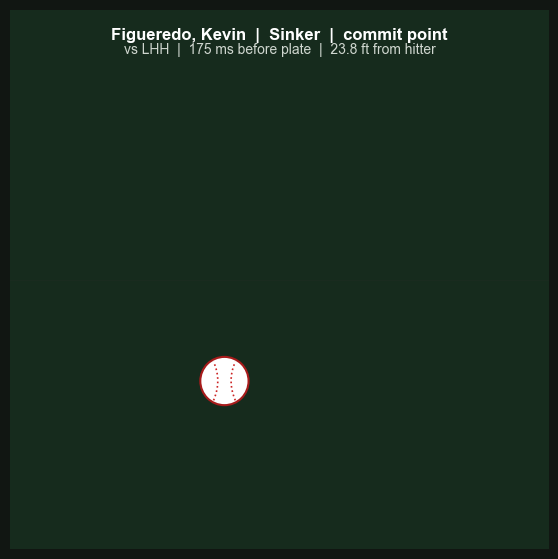

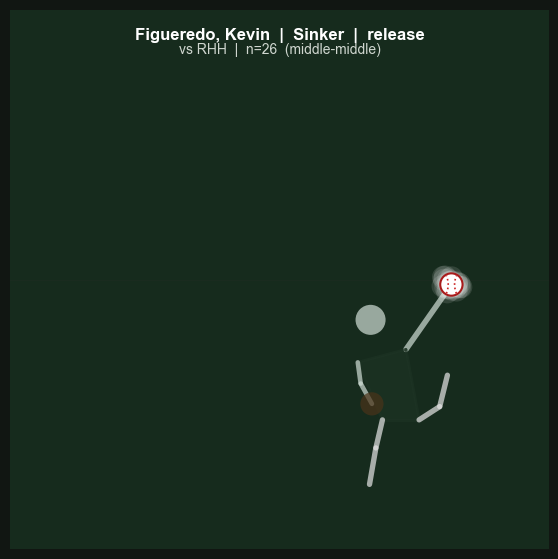

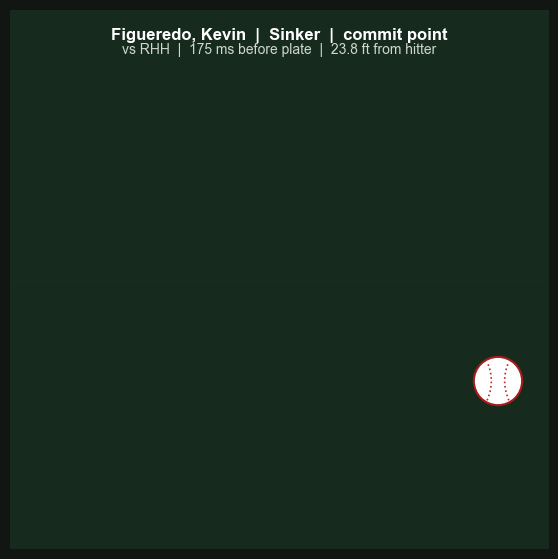

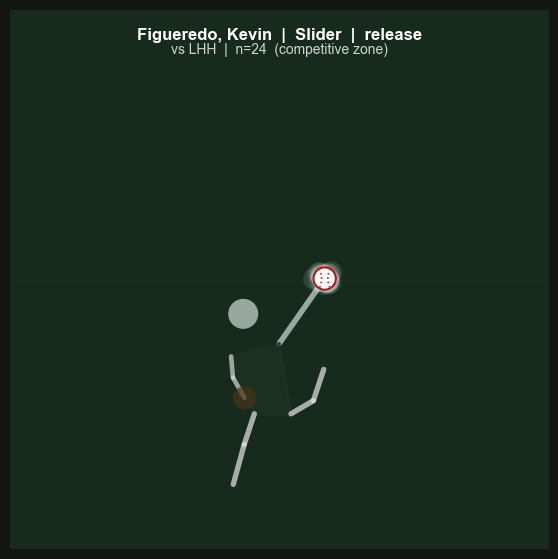

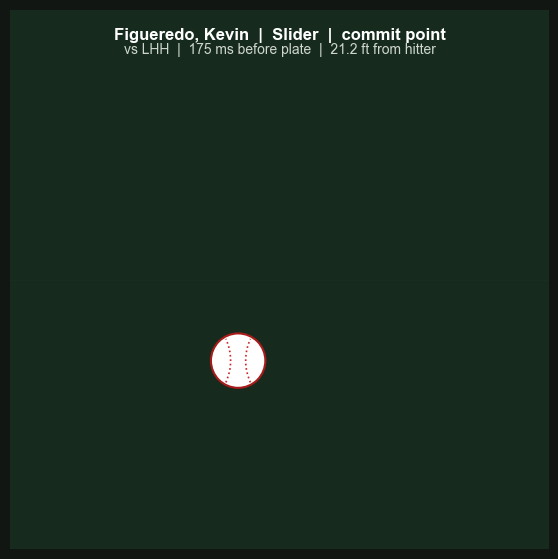

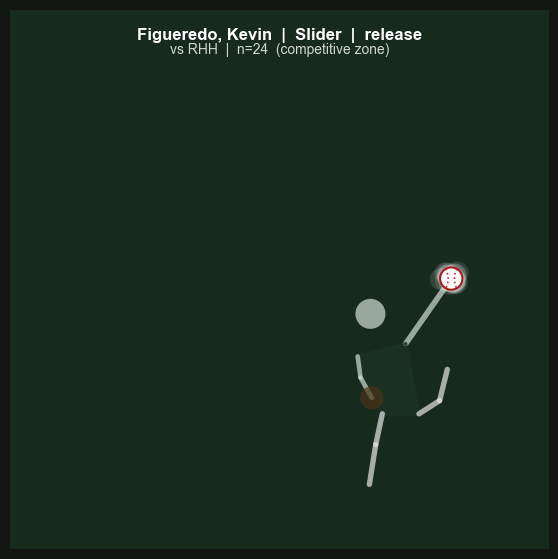

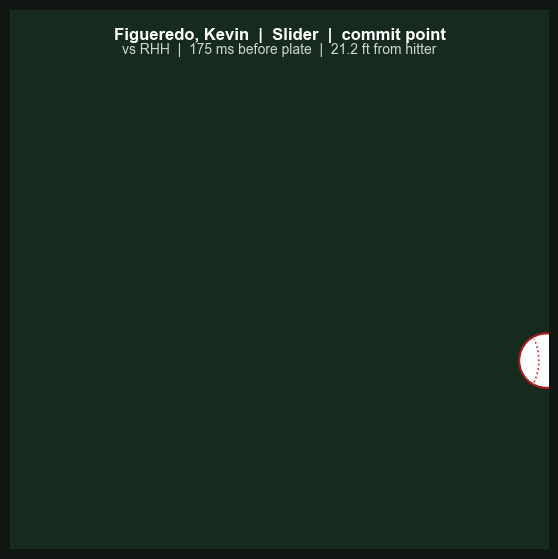


All stills saved to C:\Users\215nt\PycharmProjects\FLStuff\FLHitting\FLPitcherViz\output\figueredo_v1


In [8]:
PITCH_LABELS = {
    'four_seam': 'Four-Seam',
    'sinker':    'Sinker',
    'cutter':    'Cutter',
    'slider':    'Slider',
    'curveball': 'Curveball',
    'changeup':  'Changeup',
    'splitter':  'Splitter',
}

for pt, ref in refs.items():
    label = PITCH_LABELS.get(pt, pt.title())
    for hitter_hand in ['L', 'R']: #

        # --- 1. RENDER & SAVE RELEASE FRAME ---
        fig = rv.render_release_frame(
            ref,
            hitter_height_in=HITTER_HEIGHT_IN,
            hitter_hand=hitter_hand,
            pitcher_height_ft=PITCHER_HEIGHT_FT,
            arm_angle_deg=ARM_ANGLE_DEG,
            throwing_hand=THROWING_HAND,
            pitcher_name=PITCHER_NAME,
            pitch_type_label=label,
            style=STYLE_OVERRIDES  # <--- Pass your custom notebook style here
        )
        out = OUTPUT_DIR / f'release_{pt}_{hitter_hand}HH.png'
        # explicitly match the facecolor and remove edge padding lines
        fig.savefig(out, dpi=120, bbox_inches='tight', facecolor=fig.get_facecolor(), edgecolor='none')
        plt.show()
        plt.close(fig)

        # --- 2. RENDER & SAVE COMMIT FRAME ---
        fig = rv.render_commit_frame(
            ref,
            hitter_height_in=HITTER_HEIGHT_IN,
            hitter_hand=hitter_hand,
            pitcher_name=PITCHER_NAME,
            pitch_type_label=label,
            style=STYLE_OVERRIDES  # <--- Pass your custom notebook style here
        )
        out = OUTPUT_DIR / f'commit_{pt}_{hitter_hand}HH.png'
        fig.savefig(out, dpi=120, bbox_inches='tight', facecolor=fig.get_facecolor(), edgecolor='none')
        plt.show()
        plt.close(fig)

print(f'\nAll stills saved to {OUTPUT_DIR.resolve()}')

## Notes for iteration

**Visual tuning** (in `release_view.DEFAULTS`):
- `fov_deg` — narrower (12–16) zooms in on release; wider (20–25) gives more spatial context.
- `ball_scale` — physically correct is 1.0, but ~2.0 gives better visibility in the still. Crank to 3.0 for hitting-coach board.
- `image_size` — bump to 1200+ for prints.

**Data hygiene**
- If 2025 release point or stuff metrics drifted materially from 2026, the recency-weighted blend will undersample the recent reality. Worth a YoY sanity check on velo/IVB/HB/release_x before trusting the blend for borderline-stuff guys.
- For pitchers with <8 four-seams in middle-middle even within the competitive zone, the secondaries will be drawn from real release points but the average may be biased. Flag in the dashboard.

**Next steps queued**
- Pitch-type tunneling composite at the commit point (all pitches overlaid in one frame)
- Trap-pitch pairing (hunt pitch + layoff-side trap pitch)
- Per-count usage overlay